## Loading Data

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
AirlineDelay = pd.read_csv('Airline_Delay_Cause.csv')
#AirlineDelay = AirlineDelay.dropna()
AirlineDelay.head()


,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,...,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2015,6,AA,American Airlines Inc.,JFK,"New York, NY: John F. Kennedy International",1291.0,305.0,55.61,10.28,...,0.00,82.49,14.0,3.0,26180.0,4401.0,681.0,11266.0,0.0,9832.0
1,2015,6,AA,American Airlines Inc.,LAX,"Los Angeles, CA: Los Angeles International",2711.0,549.0,173.39,26.40,...,0.14,177.20,31.0,3.0,31561.0,10902.0,1912.0,6020.0,6.0,12721.0
2,2015,6,AA,American Airlines Inc.,DFW,"Dallas/Fort Worth, TX: Dallas/Fort Worth Inter...",12146.0,2179.0,650.52,129.06,...,4.00,824.78,144.0,71.0,173602.0,67562.0,11292.0,26810.0,194.0,67744.0
3,2015,6,AA,American Airlines Inc.,OKC,"Oklahoma City, OK: Will Rogers World",142.0,34.0,14.46,2.11,...,0.00,15.19,0.0,0.0,1938.0,872.0,69.0,124.0,0.0,873.0
4,2015,6,AA,American Airlines Inc.,OGG,"Kahului, HI: Kahului Airport",150.0,41.0,22.54,0.00,...,0.00,9.56,1.0,0.0,3794.0,1978.0,0.0,249.0,0.0,1567.0


In [5]:
ADG = AirlineDelay.groupby(['carrier','year']).sum()[['arr_del15', 'arr_flights']]
ADG.head()

arr_del15  arr_flights
carrier year                        
9E      2018    44099.0     246058.0
        2019    44331.0     257246.0
        2020    15767.0     211457.0
        2021    22726.0     266867.0
        2022    36534.0     232034.0

## Arrival Delays > 15 Min By Carrier

In [7]:
ADGByYr = ADG['arr_del15'].unstack(level=0)
AGByYr = ADG['arr_flights'].unstack(level=0)

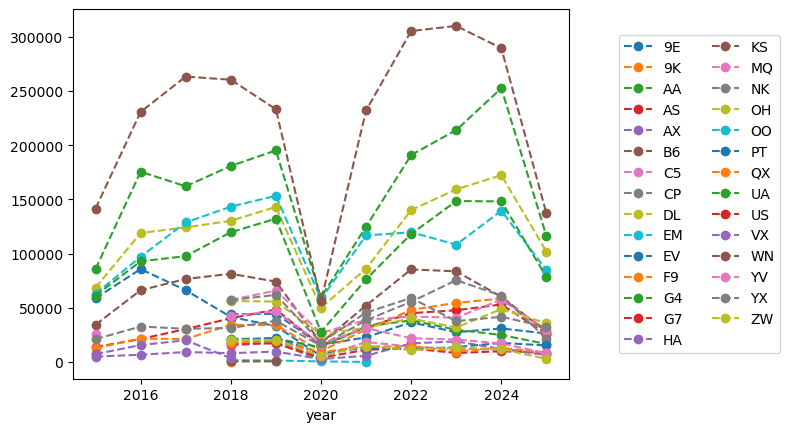

In [9]:
ADGByYr.plot(linestyle='--', marker='o')
plt.legend(ncol=2, loc=(1.1, .07))


## Number of Arrival Flights

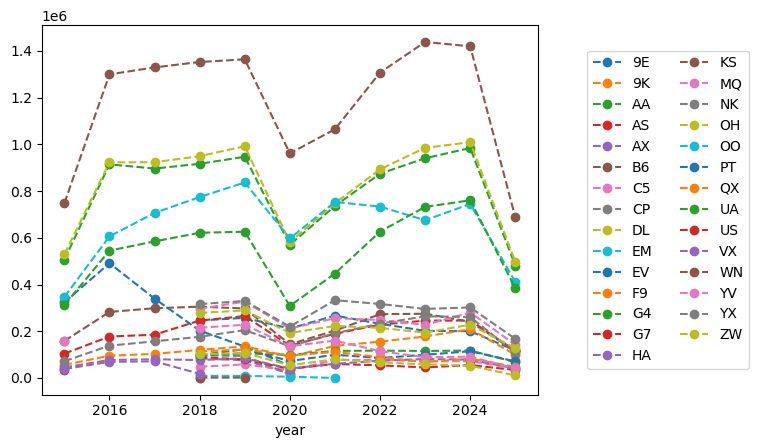

In [11]:
AGByYr.plot(linestyle='--', marker='o')
plt.legend(ncol=2, loc=(1.1, .07))

## Airport Delay Stats

In [13]:
AirlineDelay['airport_name'].value_counts()

airport_name
Cleveland, OH: Cleveland-Hopkins International           1851
Pittsburgh, PA: Pittsburgh International                 1810
Detroit, MI: Detroit Metro Wayne County                  1807
Nashville, TN: Nashville International                   1795
Indianapolis, IN: Indianapolis International             1770
                                                         ... 
Fort Collins/Loveland, CO: Northern Colorado Regional       1
Tokeen, AK: Tokeen Airport                                  1
Wendover, UT: Wendover Airport                              1
Houston, TX: Ellington                                      1
Pellston, MI: Pellston Regional Emmet County                1
Name: count, Length: 432, dtype: int64

In [33]:
APD = AirlineDelay.groupby(['airport_name', 'year']).sum()['arr_del15']

In [23]:
APD

arr_del15  arr_flights
airport_name                           year                        
Aberdeen, SD: Aberdeen Regional        2015       59.0        440.0
                                       2016       69.0        743.0
                                       2017       59.0        728.0
                                       2018       86.0        745.0
                                       2019       86.0        751.0
...                                                ...          ...
Yuma, AZ: Yuma MCAS/Yuma International 2021      303.0       1966.0
                                       2022      258.0       1655.0
                                       2023      240.0       1740.0
                                       2024      236.0       1722.0
                                       2025      166.0        873.0

[3959 rows x 2 columns]

In [35]:
APD_by_Yr = APD.unstack(level=0)

In [37]:
APD_by_Yr

airport_name,"Aberdeen, SD: Aberdeen Regional","Abilene, TX: Abilene Regional","Adak Island, AK: Adak","Aguadilla, PR: Rafael Hernandez","Akron, OH: Akron-Canton Regional","Alamosa, CO: San Luis Valley Regional/Bergman Field","Albany, GA: Southwest Georgia Regional","Albany, NY: Albany International","Albuquerque, NM: Albuquerque International Sunport","Alexandria, LA: Alexandria International",...,"Williston, ND: Sloulin Field International","Williston, ND: Williston Basin International","Wilmington, DE: New Castle","Wilmington, NC: Wilmington International","Worcester, MA: Worcester Regional","Wrangell, AK: Wrangell Airport","Yakima, WA: Yakima Air Terminal/McAllister Field","Yakutat, AK: Yakutat Airport","Youngstown/Warren, OH: Youngstown-Warren Regional","Yuma, AZ: Yuma MCAS/Yuma International"
year,,,,,,,,,,,,,,,,,,,,,
2015,59.0,173.0,8.0,264.0,657.0,NaN,125.0,967.0,2493.0,386.0,...,203.0,NaN,NaN,227.0,55.0,84.0,NaN,63.0,NaN,153.0
2016,69.0,33.0,14.0,506.0,870.0,NaN,180.0,1530.0,3382.0,449.0,...,190.0,NaN,NaN,405.0,140.0,97.0,NaN,69.0,NaN,177.0
2017,59.0,11.0,9.0,535.0,1141.0,NaN,121.0,1639.0,3582.0,271.0,...,137.0,NaN,NaN,354.0,141.0,127.0,NaN,86.0,NaN,172.0
2018,86.0,351.0,16.0,597.0,2202.0,NaN,183.0,3600.0,5440.0,554.0,...,285.0,NaN,NaN,1525.0,308.0,116.0,194.0,79.0,2.0,150.0
2019,86.0,418.0,9.0,659.0,1947.0,NaN,166.0,3835.0,5109.0,571.0,...,316.0,91.0,NaN,1686.0,359.0,143.0,210.0,120.0,NaN,288.0
2020,53.0,174.0,47.0,112.0,611.0,7.0,48.0,1054.0,1313.0,250.0,...,NaN,100.0,NaN,589.0,74.0,99.0,67.0,79.0,NaN,161.0
2021,71.0,300.0,27.0,553.0,654.0,78.0,96.0,2447.0,3875.0,418.0,...,NaN,229.0,27.0,1071.0,63.0,130.0,94.0,130.0,NaN,303.0
2022,95.0,282.0,15.0,925.0,693.0,36.0,118.0,3364.0,4638.0,355.0,...,NaN,237.0,17.0,1568.0,430.0,145.0,85.0,120.0,NaN,258.0
2023,65.0,207.0,9.0,1125.0,706.0,NaN,82.0,3044.0,5076.0,257.0,...,NaN,276.0,NaN,1276.0,309.0,120.0,28.0,113.0,NaN,240.0


In [39]:
TopN = APD_by_Yr.sum(axis=0).sort_values(ascending=False).reset_index()['airport_name'].iloc[0:19]

In [41]:
APD_by_Yr[TopN].transpose()

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
airport_name,,,,,,,,,,,
"Chicago, IL: Chicago O'Hare International",34439.0,44845.0,46519.0,79392.0,87655.0,21011.0,46281.0,51701.0,56837.0,65018.0,37148.0
"Dallas/Fort Worth, TX: Dallas/Fort Worth International",22669.0,34736.0,29245.0,52886.0,60396.0,30635.0,52081.0,53937.0,60305.0,74664.0,38433.0
"Atlanta, GA: Hartsfield-Jackson Atlanta International",32200.0,49607.0,50392.0,60608.0,55828.0,19715.0,35147.0,50355.0,55727.0,58817.0,34905.0
"Denver, CO: Denver International",22936.0,34641.0,34953.0,45025.0,56811.0,18999.0,49969.0,55721.0,62805.0,57607.0,36970.0
"Los Angeles, CA: Los Angeles International",27784.0,49065.0,52056.0,44973.0,45451.0,11179.0,28669.0,35400.0,40075.0,37409.0,17010.0
"San Francisco, CA: San Francisco International",20631.0,42671.0,49414.0,44804.0,44406.0,8369.0,15214.0,22154.0,31358.0,40386.0,15784.0
"Charlotte, NC: Charlotte Douglas International",9683.0,15678.0,16238.0,39510.0,40941.0,18514.0,27325.0,36375.0,41535.0,53683.0,24690.0
"Newark, NJ: Newark Liberty International",14832.0,26067.0,34034.0,49670.0,48155.0,9989.0,21583.0,38714.0,31301.0,29632.0,16734.0
"Orlando, FL: Orlando International",13363.0,23476.0,24811.0,29117.0,28343.0,9154.0,28415.0,40360.0,43686.0,37060.0,18550.0


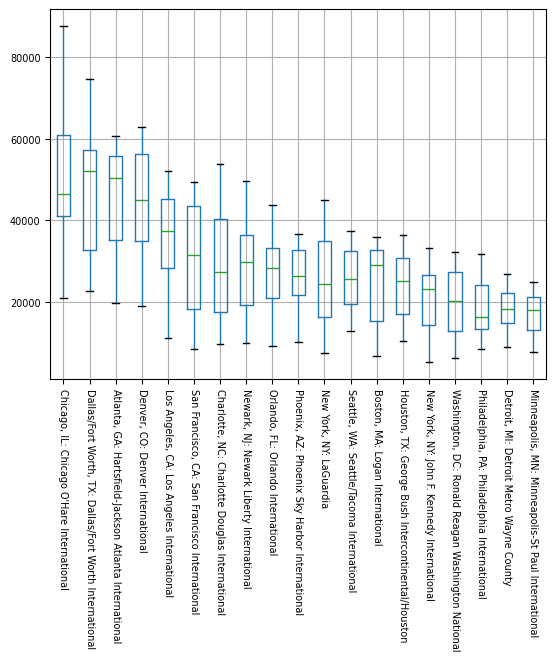

In [53]:
ax=APD_by_Yr[TopN].boxplot(fontsize=7, rot=-90)

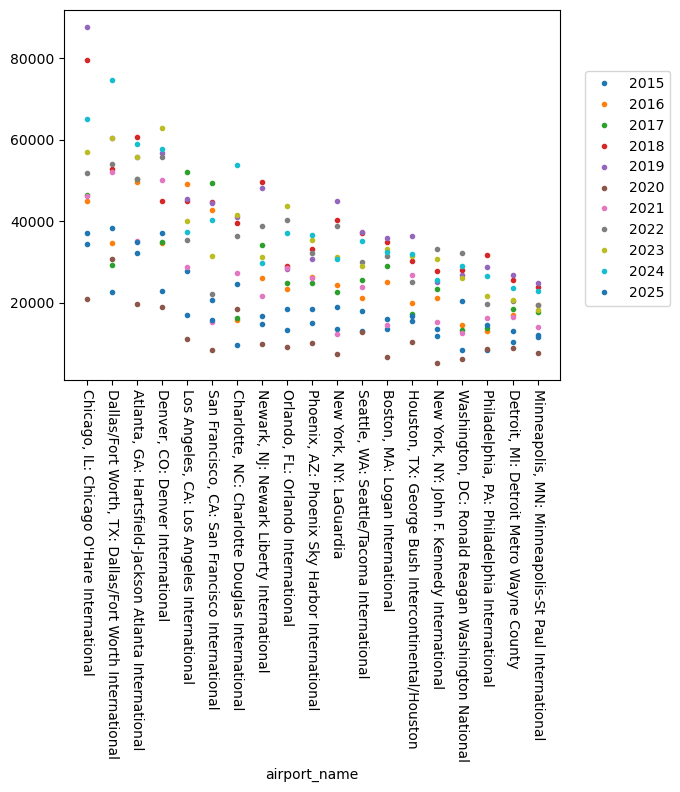

In [55]:
APD_by_Yr[TopN].transpose().plot(marker='.', linestyle='None', rot=-90)
plt.xticks(ticks=range(len(TopN)), labels=TopN)
plt.legend(loc=(1.05,.2))
plt.show()

In [57]:
def return_flight_stats(category):
    # On-Time Rate month-to-month
    OnTime_Rate = (1-AirlineDelay.groupby([category, 'year', 'month']).sum()['arr_del15']/AirlineDelay.groupby([category, 'year', 'month']).sum()['arr_flights'])*100
    # Cancel Rate month-to-month
    Cancel_Rate = (AirlineDelay.groupby([category, 'year', 'month']).sum()['arr_cancelled']/AirlineDelay.groupby([category, 'year', 'month']).sum()['arr_flights'])*100
    # Average Delay month-to-month on a per unit basis
    Avg_Delay = AirlineDelay.groupby([category, 'year', 'month']).sum()[['carrier_delay', 'weather_delay', 'nas_delay', 'security_delay', 'late_aircraft_delay']].transpose().mean()/AirlineDelay.groupby([category, 'year', 'month'])[category].value_counts() #mean()... .unstack(level=1).T
    # Delay Cause Ranked
    Ranked_DelayCauses = AirlineDelay.groupby([category, 'year', 'month']).sum()[['carrier_delay', 'weather_delay', 'nas_delay', 'security_delay', 'late_aircraft_delay']] #.rank(axis=1, ascending=False)
    return OnTime_Rate, Cancel_Rate, Avg_Delay, Ranked_DelayCauses


In [59]:
df1, df2, df3, df4 = return_flight_stats('carrier')

In [272]:
#df1.unstack(level=[1,2]).T.plot()
df4

#plt.subplot(2,1,1)
#df1.loc['MIA'].plot(linestyle='--', marker='o')
#plt.subplot(2,1,2)
#df1.loc['MIA'].groupby('year').mean().plot(linestyle='--', marker='o') 

carrier_delay  weather_delay  nas_delay  security_delay  \
carrier year month                                                            
9E      2018 1            80445.0        39907.0    58560.0             1.0   
             2            81038.0        27308.0    61735.0             0.0   
             3            80939.0         8399.0    50849.0           297.0   
             4            76497.0        19771.0    80998.0            55.0   
             5            72655.0        21827.0    68640.0            14.0   
...                           ...            ...        ...             ...   
ZW      2024 12           27696.0        11188.0    11393.0             0.0   
        2025 1            19454.0        10779.0    17875.0            43.0   
             2            22923.0        10141.0    16848.0            21.0   
             3            26443.0        10280.0    10689.0            15.0   
             4             1569.0         5413.0     2999.0             0.0   

                    late_aircraft_delay  
carrier year month                       
9E      2018 1                  88424.0  
             2                 107982.0  
             3                  89321.0  
             4                 137611.0  
             5                  86840.0  
...                                 ...  
ZW      2024 12                 35458.0  
        2025 1                  31904.0  
             2                  41296.0  
             3                  43910.0  
             4                   6314.0  

[2423 rows x 5 columns]

In [490]:
#test = AirlineDelay.groupby(['carrier', 'year']).sum()[['carrier_delay', 'weather_delay', 'nas_delay', 'security_delay', 'late_aircraft_delay']].rank(axis=1,ascending=False)

#for id in test.index:
#    test.loc[id] = test.loc[id].replace(to_replace=test.loc[id].values, value=test.columns[np.argsort(test.loc[id].values)])
#test = test.rename(columns={'carrier_delay':'1', 'weather_delay':'2', 'nas_delay':'3', 'security_delay':'4', 'late_aircraft_delay':'5'})
#test


## Forcasting

In [203]:
AirlineDelayForecast = AirlineDelay
AirlineDelayForecast['day'] = 1
AirlineDelayForecast['year_month_day'] = pd.to_datetime(AirlineDelayForecast[['year', 'month', 'day']])
AirlineDelayForecast = AirlineDelayForecast.sort_values(by=['year_month_day'])
AirlineDelayForecast['year_month_day']


207563   2015-06-01
206772   2015-06-01
206773   2015-06-01
206774   2015-06-01
206775   2015-06-01
            ...    
1306     2025-06-01
1307     2025-06-01
1308     2025-06-01
1310     2025-06-01
0        2025-06-01
Name: year_month_day, Length: 207564, dtype: datetime64[ns]

In [205]:
AirlineDelayForecast = AirlineDelayForecast.reset_index(drop=True)

In [207]:
def return_grouped_category_totals(feature):
    df = AirlineDelayForecast.groupby([feature, 'year_month_day']).sum()
    return df


In [227]:
df = return_grouped_category_totals('carrier')['arr_flights'].unstack(level=0)
# df = df.reset_index()
df

carrier,9E,9K,AA,AS,AX,B6,C5,CP,DL,EM,...,OO,PT,QX,UA,US,VX,WN,YV,YX,ZW
year_month_day,,,,,,,,,,,,,,,,,,,,,
2015-06-01,NaN,NaN,44360.0,15075.0,NaN,22558.0,NaN,NaN,77255.0,NaN,...,50307.0,NaN,NaN,46084.0,34300.0,5260.0,109776.0,NaN,NaN,NaN
2015-07-01,NaN,NaN,81434.0,15821.0,NaN,24029.0,NaN,NaN,80741.0,NaN,...,52627.0,NaN,NaN,46478.0,NaN,5411.0,113650.0,NaN,NaN,NaN
2015-08-01,NaN,NaN,79748.0,16095.0,NaN,23826.0,NaN,NaN,80947.0,NaN,...,52730.0,NaN,NaN,45413.0,NaN,5688.0,108179.0,NaN,NaN,NaN
2015-09-01,NaN,NaN,73379.0,14271.0,NaN,21133.0,NaN,NaN,72063.0,NaN,...,47625.0,NaN,NaN,41778.0,NaN,5154.0,100645.0,NaN,NaN,NaN
2015-10-01,NaN,NaN,77290.0,14467.0,NaN,21913.0,NaN,NaN,75552.0,NaN,...,48808.0,NaN,NaN,45894.0,NaN,5464.0,104516.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-02-01,16896.0,NaN,69876.0,16315.0,NaN,17685.0,5870.0,NaN,71333.0,NaN,...,59782.0,10063.0,6980.0,57628.0,NaN,NaN,100199.0,6055.0,25512.0,3627.0
2025-03-01,20649.0,NaN,82536.0,18925.0,NaN,21304.0,7299.0,NaN,84487.0,NaN,...,70500.0,12153.0,8021.0,66994.0,NaN,NaN,122432.0,7121.0,28854.0,2962.0
2025-04-01,20468.0,NaN,82261.0,19025.0,NaN,20002.0,6876.0,NaN,84188.0,NaN,...,69327.0,12129.0,8050.0,64256.0,NaN,NaN,117622.0,6772.0,28396.0,264.0


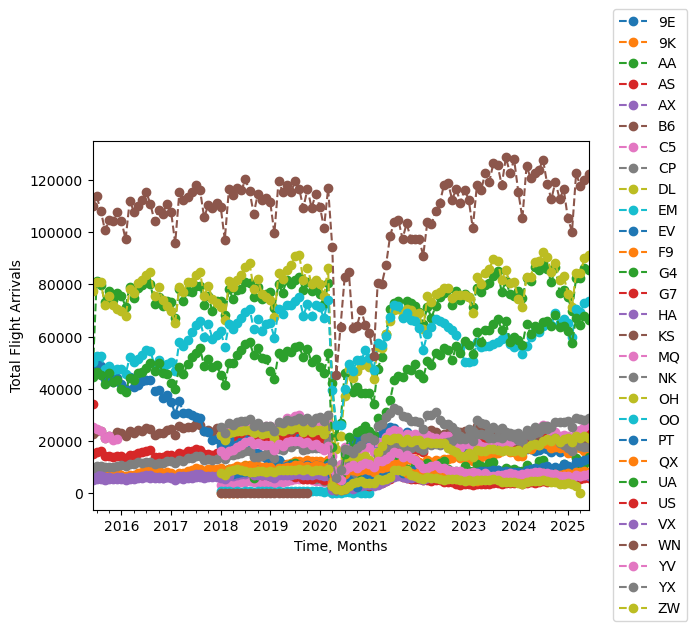

In [506]:
df.plot(linestyle='--', marker='o')
plt.ylabel('Total Flight Arrivals')
plt.xlabel('Time, Months')
plt.legend(loc=(1.05,-.3))

In [239]:
# Monthly average delay in minutes by carrier and airport
avg_monthlydelay_carrier = AirlineDelayForecast.groupby(['carrier', 'year_month_day']).sum()[['carrier_delay', 'weather_delay', 'nas_delay', 'security_delay', 'late_aircraft_delay']].transpose().mean().unstack(level=1).T
avg_monthlydelay_carrier

carrier,9E,9K,AA,AS,AX,B6,C5,CP,DL,EM,...,OO,PT,QX,UA,US,VX,WN,YV,YX,ZW
year_month_day,,,,,,,,,,,,,,,,,,,,,
2015-06-01,NaN,NaN,133202.4,17914.6,NaN,60873.6,NaN,NaN,174303.8,NaN,...,127554.6,NaN,NaN,197771.2,77108.8,11068.2,314763.8,NaN,NaN,NaN
2015-07-01,NaN,NaN,180586.0,20265.0,NaN,63091.6,NaN,NaN,144367.0,NaN,...,122854.0,NaN,NaN,157210.2,NaN,12750.0,325811.6,NaN,NaN,NaN
2015-08-01,NaN,NaN,172559.8,24533.4,NaN,74829.0,NaN,NaN,138084.6,NaN,...,110776.6,NaN,NaN,115378.4,NaN,11506.2,236330.4,NaN,NaN,NaN
2015-09-01,NaN,NaN,111052.8,14232.4,NaN,44974.8,NaN,NaN,75065.2,NaN,...,74722.8,NaN,NaN,66649.0,NaN,6061.0,115222.4,NaN,NaN,NaN
2015-10-01,NaN,NaN,117738.4,14276.0,NaN,42458.8,NaN,NaN,66273.0,NaN,...,72682.0,NaN,NaN,68594.4,NaN,9963.4,123459.2,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-02-01,48640.2,NaN,222744.0,35590.6,NaN,76387.2,22180.0,NaN,198610.4,NaN,...,227078.0,39198.0,18684.2,144580.6,NaN,NaN,185144.8,16035.4,70825.0,18245.8
2025-03-01,60815.8,NaN,301789.6,36111.2,NaN,74975.8,19262.6,NaN,223168.8,NaN,...,218703.2,30677.8,13931.2,159521.6,NaN,NaN,256281.2,19194.8,61946.2,18267.4
2025-04-01,71264.2,NaN,305063.2,34722.0,NaN,43313.8,15478.0,NaN,202749.2,NaN,...,187165.6,34210.0,10806.4,172666.4,NaN,NaN,252667.2,16426.8,53930.4,3259.0


In [502]:
# Delay cause ranking over months
# rankdelay_monthly_carrier = AirlineDelayForecast.groupby(['carrier', 'year_month_day']).sum()[['carrier_delay', 'weather_delay', 'nas_delay', 'security_delay', 'late_aircraft_delay']].rank(axis=1, ascending=False)
# rankdelay_monthly_airport = AirlineDelayForecast.groupby(['airport', 'year_month_day']).sum()[['carrier_delay', 'weather_delay', 'nas_delay', 'security_delay', 'late_aircraft_delay']].rank(axis=1, ascending=False)
# rankdelay_monthly_airport

carrier_delay  weather_delay  nas_delay  \
airport year_month_day                                            
ABE     2015-06-01                2.0            3.0        4.0   
        2015-07-01                1.0            4.0        2.0   
        2015-08-01                1.0            4.0        3.0   
        2015-09-01                1.0            2.0        3.0   
        2015-10-01                1.0            4.5        3.0   
...                               ...            ...        ...   
YUM     2025-02-01                1.0            3.0        4.0   
        2025-03-01                1.0            3.0        4.0   
        2025-04-01                1.0            3.0        4.0   
        2025-05-01                1.0            2.0        3.0   
        2025-06-01                1.0            4.0        3.0   

                        security_delay  late_aircraft_delay  
airport year_month_day                                       
ABE     2015-06-01                 5.0                  1.0  
        2015-07-01                 5.0                  3.0  
        2015-08-01                 5.0                  2.0  
        2015-09-01                 5.0                  4.0  
        2015-10-01                 4.5                  2.0  
...                                ...                  ...  
YUM     2025-02-01                 5.0                  2.0  
        2025-03-01                 5.0                  2.0  
        2025-04-01                 5.0                  2.0  
        2025-05-01                 5.0                  4.0  
        2025-06-01                 5.0                  2.0  

[41767 rows x 5 columns]